In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Wage-setting institutions and the pass-through of inflation to wages
Notebook 26 found that wage pass-through is weak and differs across countries, with none detectable in the 2021-23 energy shock. Here the cross-country differences are set against **collective-bargaining coverage** and **trade-union density** (OECD/AIAS, from the ICTWSS database, via the OECD SDMX API: `sources/oecd_bargaining.py`; per cent of employees, country means over 2005-2019).
**Design (one cross-section, so low power).** The country pass-through is the one of notebook 26 (monthly labour cost on inflation, 2005Q1-2021Q2, `hf.passthrough_by_country`, 27 countries). Two pre-specified institution variables; Spearman correlation with a **permutation p-value** (institution shuffled across countries), Benjamini-Hochberg over the two; leave-one-country-out; robustness without Greece and Portugal (negative estimates), with 2010-2019 means and with at least six observations per mean; shuffled null; Italy by position among the countries (rank), not by a test.
**Data notes.** Coverage is observed in few years for several countries (2-4 values for Estonia, Finland, Luxembourg, Latvia, Slovenia, Ireland, Slovakia), so its mean uses the years available; Italy's coverage is recorded as **100% in every year** (a top-coded point: minimum pay in collective contracts is extended by case law). Union density is observed in most years. **Associations only, never causal.** Code: `src/cifresignificative/studies/italy_productivity/analysis/bargaining.py`, `experiments.run_bargaining_all`.

countries with a pass-through estimate and an institution mean: 23 | with coverage: 21 | with union density: 23


iso3,GRC,PRT,GBR,SWE,SVN,IRL,ESP,CZE,ITA,POL,...,DNK,DEU,AUT,LUX,FIN,NLD,HUN,BEL,LVA,EST
cbc,57.62,89.13,45.18,88.57,88.27,38.73,NaN,46.10,100.00,16.40,...,83.40,58.61,98.00,57.78,89.00,78.09,23.77,100.00,31.63,NaN
tud,18.40,17.99,25.84,68.74,26.14,28.53,14.89,13.83,32.13,16.29,...,64.57,16.99,24.77,35.26,68.33,17.98,13.37,53.84,13.92,6.44
pass_through,-1.96,-0.74,-0.07,-0.06,0.22,0.25,0.27,0.30,0.31,0.39,...,0.50,0.50,0.52,0.53,0.54,0.62,0.71,0.71,0.96,0.97


primary tests and robustness (rho = Spearman with the country pass-through; negative = more bargaining goes with less pass-through):


,spec,variable,n,rho,p,q_value,loo_min_abs_rho,loo_sign_flips
0,primary,cbc,21,0.001,0.997,0.997,0.001,14
1,primary,tud,23,-0.200,0.357,0.714,0.085,0
2,without GRC and PRT,cbc,19,0.042,0.862,0.862,0.002,6
3,without GRC and PRT,tud,21,-0.203,0.383,0.765,0.077,0
4,2010-19 means,cbc,17,0.033,0.901,0.901,0.001,6
5,2010-19 means,tud,22,-0.110,0.625,0.901,0.014,1
6,at least 6 observations,cbc,15,0.172,0.535,0.575,0.000,1
7,at least 6 observations,tud,21,-0.131,0.575,0.575,0.006,1


Italy among the countries with data:


,variable,n,italy,median_others,rank_1_highest
0,pass_through,23,0.31,0.46,15
1,cbc,21,100.00,58.19,1
2,tud,23,32.13,17.98,6


shuffled pass-through, 500 repetitions: discoveries per repetition 0.04 | repetitions with a discovery 0.038 | share of tests with p < 0.05 0.042


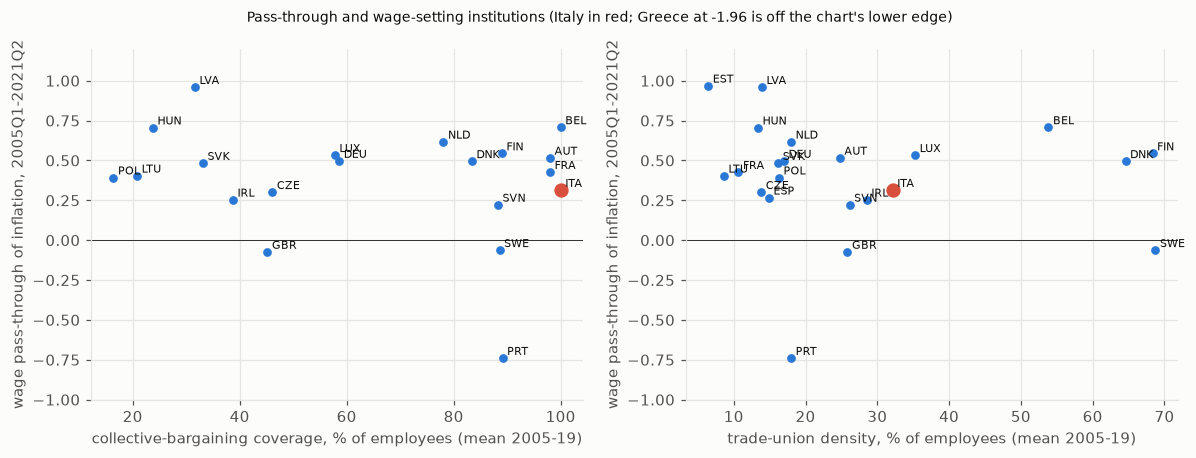

In [2]:
from cifresignificative.studies.italy_productivity.analysis import bargaining as BGN, experiments as ex, hf as H
res = ex.run_bargaining_all()
inst = res["w1_institutions"].set_index("iso3")
pt = H.passthrough_by_country(H.load_highfreq(), ("2005-01-01", "2021-06-30")).set_index("iso3")
j = inst.join(pt.pass_through, how="inner").sort_values("pass_through")
print("countries with a pass-through estimate and an institution mean:", len(j), "| with coverage:", int(j.cbc.notna().sum()), "| with union density:", int(j.tud.notna().sum())); display(j.round(2).T)
print("primary tests and robustness (rho = Spearman with the country pass-through; negative = more bargaining goes with less pass-through):")
display(res["w2_association"][["spec", "variable", "n", "rho", "p", "q_value", "loo_min_abs_rho", "loo_sign_flips"]].round(3))
print("Italy among the countries with data:"); display(res["w3_italy"].round(2))
n0 = res["w4_null"].iloc[0]; print("shuffled pass-through,", int(n0.n_rep), "repetitions: discoveries per repetition", round(float(n0.mean_discoveries), 3), "| repetitions with a discovery", round(float(n0.share_reps_with_discovery), 3), "| share of tests with p < 0.05", round(float(n0.mean_share_p_below_005), 3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, v, lab in [(axes[0], "cbc", "collective-bargaining coverage, % of employees (mean 2005-19)"), (axes[1], "tud", "trade-union density, % of employees (mean 2005-19)")]:
    for c, r in j.dropna(subset=[v]).iterrows():
        ax.scatter(r[v], r.pass_through, s=70 if c == "ITA" else 22, color="#d94f3d" if c == "ITA" else "#2a78d6"); ax.annotate(c, (r[v], r.pass_through), fontsize=7, xytext=(3, 2), textcoords="offset points")
    ax.axhline(0, color="k", lw=0.5); ax.set_xlabel(lab); ax.set_ylabel("wage pass-through of inflation, 2005Q1-2021Q2")
fig.suptitle("Pass-through and wage-setting institutions (Italy in red; Greece at -1.96 is off the chart's lower edge)", fontsize=9); ax.set_ylim(-1.0, 1.2); axes[0].set_ylim(-1.0, 1.2)
plt.tight_layout(); plt.show()

## Takeaways (OECD/AIAS bargaining coverage and union density, means 2005-2019; pass-through of notebook 26, 2005Q1-2021Q2; descriptive)
- **No relation between wage-setting institutions and pass-through across countries.** Across 21 countries with coverage and 23 with union density, the Spearman correlation with the country pass-through is 0.00 for coverage (permutation p 0.997) and -0.20 for union density (p 0.36, q 0.71 over the two tests). The robustness runs stay in the same range (coverage 0.03 to 0.17, union density -0.20 to -0.11; smallest p 0.36 over all eight rows). The sign of the coverage relation is not stable (removing a single country flips it in 14 of 21 leave-one-out runs). Shuffling the pass-through gives 0.04 discoveries per repetition (500 repetitions), so the procedure does not manufacture them.
- **Italy.** Coverage is recorded as 100% in every year, the joint highest with Belgium (median of the other countries 58%); union density is 32.1% (rank 6 of 23, median 18.0%). Its pass-through, 0.31, is below the median of the others (0.46; rank 15 of 23). The most extreme estimates are Greece (-1.96) and Portugal (-0.74); the tests use ranks, and dropping both changes nothing.
- **What the test can and cannot say.** With 21-23 countries only a rank correlation of about 0.4 or more (1.96 / sqrt(n - 1), an approximation) can be told from zero, and each country's pass-through is itself a noisy estimate (standard errors of 0.2-0.4 are common in notebook 26): a moderate link would not show. Coverage is observed in 2-4 years for several countries (means of few values), Italy's coverage is a top-coded point, and both institutions are slow-moving national averages that miss what matters for timing (contract renewal lags, sector agreements, indexation clauses).
- **Limits.** One cross-section, no sector or contract-level information, pass-through from monthly labour costs on HICP inflation (notebook 26), a third factor could drive both institutions and pass-through, and the energy-shock window (2021Q3-2023Q4) is too short for country estimates. Nothing here is causal.
